# Clasificación de Fallas en Motores (EngineFaultDB) usando MLP y Reducción de Dimensionalidad

Este notebook presenta un flujo de trabajo estructurado para entrenar un modelo de Perceptrón Multicapa (MLP) y evaluar técnicas de reducción de dimensiones (PCA y UMAP) junto con estrategias de balanceo de clases.

In [3]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
SEED = 42
np.random.seed(SEED)

In [4]:
# Subir el CSV (alternativa: montar Drive y leer desde allí)
from google.colab import files
uploaded = files.upload()   # selecciona EngineFaultDB_Final.csv
CSV_PATH = list(uploaded.keys())[0]

Saving EngineFaultDB_Final.csv to EngineFaultDB_Final.csv


## Parte 1: Carga, Preparación y Partición de Datos

In [5]:
df = pd.read_csv(CSV_PATH)
X = df.drop(columns=["Fault"])
y = df["Fault"]

print("Dimensiones:", df.shape)
print("Distribución de clases:\n", y.value_counts(normalize=True).sort_index())

# Test set separado (20 %), nunca se toca durante el ajuste de hiperparámetros
# OJO: los folds son de diferente tamaño en el MLP y el random forest (70/30). Para ser resultados comparables se debe separar equitativamente
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

Dimensiones: (55999, 15)
Distribución de clases:
 Fault
0    0.285719
1    0.196396
2    0.267862
3    0.250022
Name: proportion, dtype: float64


## Parte 2: Optimización de Hiperparámetros del MLP (GridSearch)

In [6]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(solver="adam",
                          max_iter=300,
                          early_stopping=True,     # usa 10 % interno como validación
                          n_iter_no_change=15,
                          random_state=SEED)),
])

param_grid = {
    "mlp__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [1e-4, 1e-3, 1e-2],              # regularización L2
    "mlp__learning_rate_init": [1e-3, 1e-2],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

grid = GridSearchCV(
    pipe,
    param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1,
)
grid.fit(X_train, y_train)

print("\nMejores hiperparámetros:", grid.best_params_)
print("Mejor F1-macro (validación CV): %.4f" % grid.best_score_)

Fitting 5 folds for each of 60 candidates, totalling 300 fits

Mejores hiperparámetros: {'mlp__activation': 'tanh', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': 0.01}
Mejor F1-macro (validación CV): 0.7552


## Parte 3: Evaluación del Modelo Óptimo (Base)

In [7]:
res = pd.DataFrame(grid.cv_results_)
cols = ["param_mlp__hidden_layer_sizes", "param_mlp__activation",
        "param_mlp__alpha", "param_mlp__learning_rate_init",
        "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
res_tab = res[cols].rename(columns={
    "param_mlp__hidden_layer_sizes": "capas_ocultas",
    "param_mlp__activation": "activacion",
    "param_mlp__alpha": "alpha",
    "param_mlp__learning_rate_init": "lr_inicial",
    "mean_train_score": "F1_train",
    "mean_test_score": "F1_val",
    "std_test_score": "std_val",
    "rank_test_score": "ranking",
}).sort_values("ranking")
res_tab.to_csv("resultados_malla_mlp.csv", index=False)
print("\nTop 10 configuraciones:\n", res_tab.head(10).to_string(index=False))


Top 10 configuraciones:
 capas_ocultas activacion  alpha  lr_inicial  F1_train   F1_val  std_val  ranking
        (64,)       tanh 0.0010       0.010  0.759846 0.755207 0.004669        1
        (64,)       relu 0.0010       0.001  0.759886 0.753524 0.002899        2
        (64,)       relu 0.0100       0.001  0.759466 0.752766 0.005338        3
        (64,)       relu 0.0001       0.001  0.759490 0.752628 0.002751        4
        (64,)       tanh 0.0100       0.010  0.754129 0.752159 0.010776        5
     (64, 32)       relu 0.0001       0.001  0.754104 0.751782 0.003815        6
        (64,)       tanh 0.0001       0.001  0.757687 0.751725 0.009769        7
        (64,)       tanh 0.0001       0.010  0.755909 0.751392 0.005569        8
        (32,)       tanh 0.0100       0.001  0.757756 0.751345 0.003026        9
     (32, 16)       tanh 0.0100       0.010  0.756414 0.751102 0.005122       10


## 4. Gráficas del efecto de los hiperparámetros

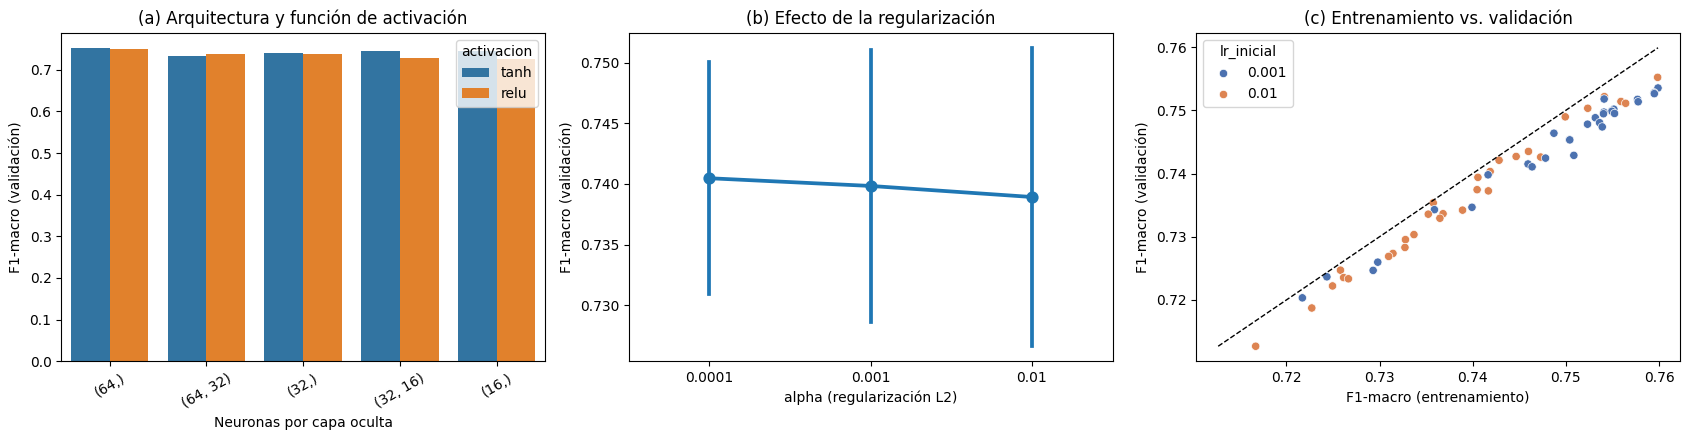

In [8]:
res_plot = res_tab.copy()
res_plot["capas_ocultas"] = res_plot["capas_ocultas"].astype(str)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) arquitectura x activación
sns.barplot(data=res_plot, x="capas_ocultas", y="F1_val", hue="activacion",
            errorbar=None, ax=axes[0])
axes[0].set_xlabel("Neuronas por capa oculta")
axes[0].set_ylabel("F1-macro (validación)")
axes[0].set_title("(a) Arquitectura y función de activación")
axes[0].tick_params(axis="x", rotation=30)

# (b) alpha
sns.pointplot(data=res_plot, x="alpha", y="F1_val", errorbar="sd", ax=axes[1])
axes[1].set_xlabel("alpha (regularización L2)")
axes[1].set_ylabel("F1-macro (validación)")
axes[1].set_title("(b) Efecto de la regularización")

# (c) train vs validación (sobreajuste)
sns.scatterplot(data=res_plot, x="F1_train", y="F1_val",
                hue="lr_inicial", palette="deep", ax=axes[2])
lims = [res_plot[["F1_train", "F1_val"]].min().min(),
        res_plot[["F1_train", "F1_val"]].max().max()]
axes[2].plot(lims, lims, "k--", lw=1)
axes[2].set_xlabel("F1-macro (entrenamiento)")
axes[2].set_ylabel("F1-macro (validación)")
axes[2].set_title("(c) Entrenamiento vs. validación")

plt.tight_layout()
plt.savefig("efecto_hiperparametros_mlp.png", dpi=300)
plt.show()

## 5. Métricas con intervalos de confianza

In [9]:
best_model = grid.best_estimator_

# 5.1 Train y validación: validación cruzada con el mejor modelo
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro",
}
cv_res = cross_validate(best_model, X_train, y_train, cv=cv, scoring=scoring,
                        return_train_score=True, n_jobs=-1)


def ic_t(valores, conf=0.95):
    """Intervalo de confianza t de Student para la media de los folds."""
    valores = np.asarray(valores)
    m = valores.mean()
    h = stats.sem(valores) * stats.t.ppf((1 + conf) / 2, len(valores) - 1)
    return m, m - h, m + h


filas = []
for met in scoring:
    for fase, clave in [("Entrenamiento", f"train_{met}"), ("Validación", f"test_{met}")]:
        m, lo, hi = ic_t(cv_res[clave])
        filas.append({"Fase": fase, "Métrica": met, "Media": m, "IC95_inf": lo, "IC95_sup": hi})

# 5.2 Test: IC por bootstrap sobre las predicciones
y_pred = best_model.predict(X_test)
y_test_arr = y_test.to_numpy()


def bootstrap_ic(metric_fn, y_true, y_hat, n_boot=1000, conf=0.95, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        vals.append(metric_fn(y_true[idx], y_hat[idx]))
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return metric_fn(y_true, y_hat), lo, hi


metricas_test = {
    "accuracy": accuracy_score,
    "precision": lambda a, b: precision_score(a, b, average="macro", zero_division=0),
    "recall": lambda a, b: recall_score(a, b, average="macro", zero_division=0),
    "f1": lambda a, b: f1_score(a, b, average="macro"),
}
for nombre, fn in metricas_test.items():
    m, lo, hi = bootstrap_ic(fn, y_test_arr, y_pred)
    filas.append({"Fase": "Test", "Métrica": nombre, "Media": m, "IC95_inf": lo, "IC95_sup": hi})

tabla_final = pd.DataFrame(filas)
tabla_final.to_csv("metricas_mlp.csv", index=False)
print("\nMétricas del mejor MLP (IC 95 %):\n", tabla_final.round(4).to_string(index=False))

print("\nReporte de clasificación (test):\n", classification_report(y_test, y_pred, digits=4))


Métricas del mejor MLP (IC 95 %):
          Fase   Métrica  Media  IC95_inf  IC95_sup
Entrenamiento  accuracy 0.7529    0.7506    0.7553
   Validación  accuracy 0.7483    0.7428    0.7537
Entrenamiento precision 0.7630    0.7608    0.7652
   Validación precision 0.7584    0.7540    0.7628
Entrenamiento    recall 0.7627    0.7607    0.7646
   Validación    recall 0.7581    0.7538    0.7625
Entrenamiento        f1 0.7598    0.7564    0.7633
   Validación        f1 0.7552    0.7487    0.7617
         Test  accuracy 0.7459    0.7382    0.7539
         Test precision 0.7480    0.7398    0.7559
         Test    recall 0.7490    0.7443    0.7536
         Test        f1 0.7217    0.7158    0.7275

Reporte de clasificación (test):
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     0.9968    0.9995    0.9982      2200
           2     0.5166    0.8240    0.6351      3000
           3     0.4787    0.1725    0.2536      

## Parte 4: Reducción de Dimensionalidad Lineal (PCA)

Estandarizamos las características y aplicamos Análisis de Componentes Principales (PCA) para reducir las dimensiones conservando la mayor varianza posible.

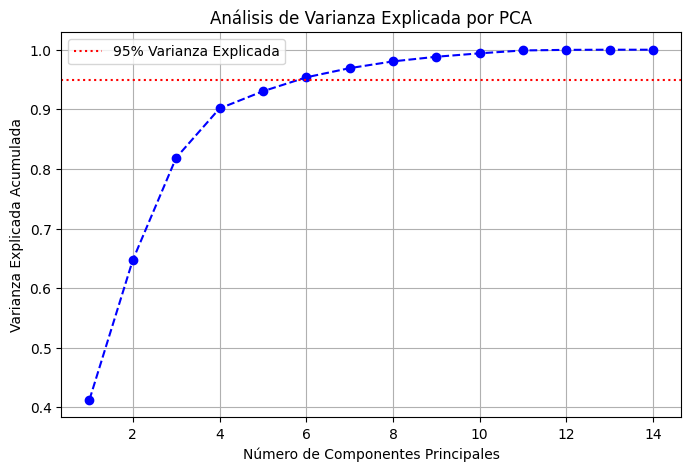

Número de componentes para explicar al menos el 95% de la varianza: 6


In [10]:
from sklearn.decomposition import PCA

# Ajustamos el escalador con los datos de entrenamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aplicamos PCA sin limitar inicialmente el número de componentes
pca = PCA(random_state=SEED)
pca.fit(X_train_scaled)

# Calculamos la varianza explicada acumulada
var_acumulada = np.cumsum(pca.explained_variance_ratio_)

# Visualizamos la varianza explicada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(var_acumulada) + 1), var_acumulada, marker='o', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle=':', label='95% Varianza Explicada')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada Acumulada')
plt.title('Análisis de Varianza Explicada por PCA')
plt.legend(loc='best')
plt.grid(True)
plt.show()

# Mostrar cuántos componentes se necesitan para el 95%
n_comp_95 = np.argmax(var_acumulada >= 0.95) + 1
print(f"Número de componentes para explicar al menos el 95% de la varianza: {n_comp_95}")

### Proyección y Visualización en 2D con PCA

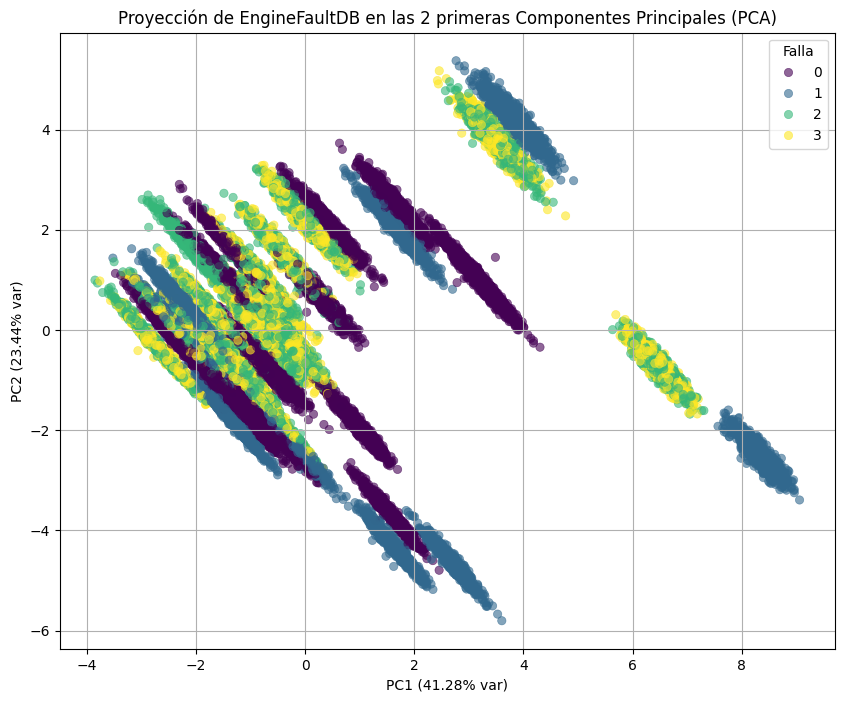

In [11]:
# Proyectamos los datos de entrenamiento en las 2 primeras componentes
X_train_pca2 = pca.transform(X_train_scaled)[:, :2]

df_pca2 = pd.DataFrame(X_train_pca2, columns=['PC1', 'PC2'])
df_pca2['Fault'] = y_train.values

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df_pca2,
    x='PC1',
    y='PC2',
    hue='Fault',
    palette='viridis',
    alpha=0.6,
    edgecolor=None
)
plt.title('Proyección de EngineFaultDB en las 2 primeras Componentes Principales (PCA)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% var)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% var)')
plt.legend(title='Falla')
plt.grid(True)
plt.show()

### Entrenamiento del MLP con 6 Componentes Principales

In [12]:
# Definimos el pipeline con 6 componentes de PCA y los mejores hiperparámetros del GridSearch
pca_mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=6, random_state=SEED)),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64,),
        activation='tanh',
        alpha=0.001,
        learning_rate_init=0.01,
        solver="adam",
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=SEED
    ))
])

# Entrenamos el pipeline con los datos de entrenamiento originales
pca_mlp_pipe.fit(X_train, y_train)

# Realizamos predicciones en el conjunto de prueba
y_pred_pca = pca_mlp_pipe.predict(X_test)

# Reporte de clasificación final con PCA
print("\nReporte de clasificación con 6 componentes de PCA (test):\n")
print(classification_report(y_test, y_pred_pca, digits=4))


Reporte de clasificación con 6 componentes de PCA (test):

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     1.0000    1.0000    1.0000      2200
           2     0.5173    0.8640    0.6471      3000
           3     0.4829    0.1361    0.2123      2800

    accuracy                         0.7476     11200
   macro avg     0.7500    0.7500    0.7149     11200
weighted avg     0.7414    0.7476    0.7086     11200



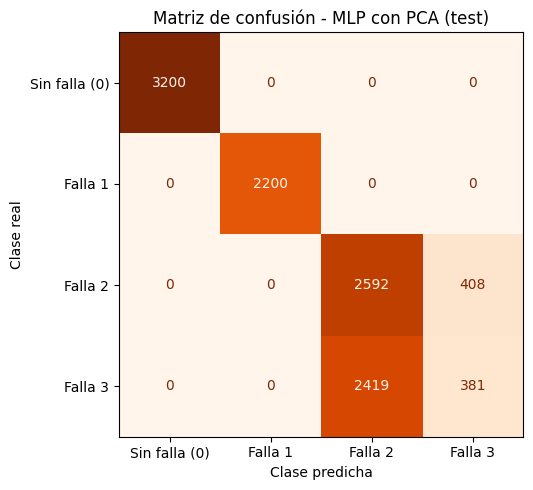

In [13]:
# Generamos y graficamos la matriz de confusión para el modelo con PCA
cm_pca = confusion_matrix(y_test, y_pred_pca)
disp_pca = ConfusionMatrixDisplay(cm_pca, display_labels=["Sin falla (0)", "Falla 1", "Falla 2", "Falla 3"])

fig, ax = plt.subplots(figsize=(6, 5))
disp_pca.plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_title("Matriz de confusión - MLP con PCA (test)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.tight_layout()
plt.savefig("matriz_confusion_mlp_pca.png", dpi=300)
plt.show()

### Diagnóstico: Análisis de Solapamiento entre Clase 2 y Clase 3

In [14]:
# 1. Analizar el balance de clases en el conjunto de entrenamiento
print("Distribución de clases en entrenamiento:")
print(y_train.value_counts().sort_index())

# 2. Obtener las coordenadas de las 6 componentes de PCA
X_train_pca6 = pca.transform(X_train_scaled)[:, :6]
df_pca6 = pd.DataFrame(X_train_pca6, columns=[f'PC{i}' for i in range(1, 7)])
df_pca6['Fault'] = y_train.values

# Calcular los centroides (media) de cada clase en el espacio de 6 dimensiones de PCA
centroides = df_pca6.groupby('Fault').mean()
print("\nCentroides de cada clase en las 6 componentes principales:")
display(centroides)

# Calcular las distancias Euclidianas entre los centroides de las clases
from scipy.spatial.distance import pdist, squareform
distancias = squareform(pdist(centroides))
df_distancias = pd.DataFrame(distancias, index=centroides.index, columns=centroides.index)
print("\nMatriz de distancias Euclidianas entre centroides de clases (en espacio PCA 6D):")
display(df_distancias)

Distribución de clases en entrenamiento:
Fault
0    12800
1     8798
2    12000
3    11201
Name: count, dtype: int64

Centroides de cada clase en las 6 componentes principales:


,PC1,PC2,PC3,PC4,PC5,PC6
Fault,,,,,,
0,-0.036106,-0.161719,-0.421778,0.136725,-0.150827,-0.109309
1,0.752059,-0.782451,0.071668,0.541227,0.147377,-0.195377
2,-0.325375,0.428839,0.271140,-0.251984,-0.006822,0.168628
3,-0.200871,0.339965,0.135215,-0.311399,0.063908,0.097718



Matriz de distancias Euclidianas entre centroides de clases (en espacio PCA 6D):


Fault,0,1,2,3
Fault,,,,
0,0.000000,1.228804,1.077800,0.937477
1,1.228804,0.000000,1.858316,1.729675
2,1.077800,1.858316,0.000000,0.235449
3,0.937477,1.729675,0.235449,0.000000


## Parte 5: Estrategia de Mitigación - Submuestreo de la Clase 2

In [15]:
# Identificamos los índices de cada clase en el conjunto de entrenamiento
idx_0 = y_train[y_train == 0].index
idx_1 = y_train[y_train == 1].index
idx_2 = y_train[y_train == 2].index
idx_3 = y_train[y_train == 3].index

# Determinamos el tamaño objetivo (el de la clase 3)
target_size = len(idx_3)

# Submuestreamos la clase 2 aleatoriamente para igualar a la clase 3
np.random.seed(SEED)
idx_2_downsampled = np.random.choice(idx_2, size=target_size, replace=False)

# Unimos los nuevos índices balanceados
balanced_indices = np.concatenate([idx_0, idx_1, idx_2_downsampled, idx_3])

X_train_bal = X_train.loc[balanced_indices]
y_train_bal = y_train.loc[balanced_indices]

print("Nueva distribución de clases en el entrenamiento balanceado:")
print(y_train_bal.value_counts().sort_index())

# Volvemos a entrenar el pipeline de PCA (6 componentes) + MLP con los datos balanceados
pca_mlp_pipe.fit(X_train_bal, y_train_bal)
y_pred_bal = pca_mlp_pipe.predict(X_test)

print("\nReporte de clasificación con Clase 2 submuestreada (test):\n")
print(classification_report(y_test, y_pred_bal, digits=4))

Nueva distribución de clases en el entrenamiento balanceado:
Fault
0    12800
1     8798
2    11201
3    11201
Name: count, dtype: int64

Reporte de clasificación con Clase 2 submuestreada (test):

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     1.0000    1.0000    1.0000      2200
           2     0.5516    0.3420    0.4222      3000
           3     0.4990    0.7021    0.5834      2800

    accuracy                         0.7493     11200
   macro avg     0.7626    0.7610    0.7514     11200
weighted avg     0.7546    0.7493    0.7411     11200



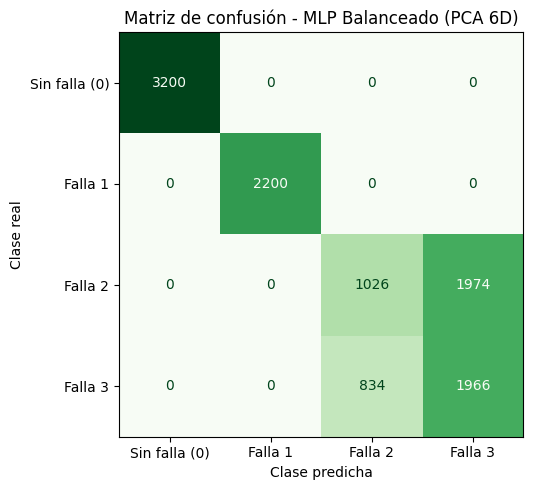

In [16]:
# Graficamos la nueva matriz de confusión
cm_bal = confusion_matrix(y_test, y_pred_bal)
disp_bal = ConfusionMatrixDisplay(cm_bal, display_labels=["Sin falla (0)", "Falla 1", "Falla 2", "Falla 3"])

fig, ax = plt.subplots(figsize=(6, 5))
disp_bal.plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Matriz de confusión - MLP Balanceado (PCA 6D)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

## Parte 6: Reducción de Dimensionalidad No Lineal (UMAP)

Utilizamos UMAP para mapear los datos a un espacio de baja dimensionalidad preservando las relaciones de vecindad local.

In [17]:
!pip install -q umap-learn

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


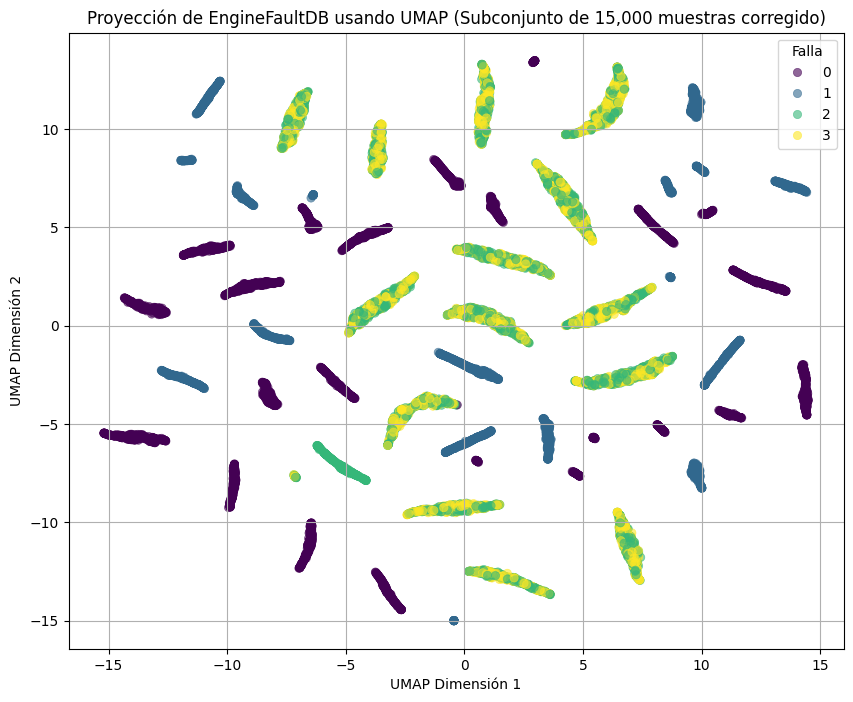

In [18]:
import umap
from sklearn.preprocessing import StandardScaler

# Reducimos usando UMAP (se suele usar una muestra o el dataset de entrenamiento si el tiempo lo permite)
# Para agilizar la ejecución y evitar tiempos de espera prolongados en Colab, tomamos un subconjunto aleatorio representativo
np.random.seed(SEED)

# 1. Escalamos los datos de entrenamiento primero de manera limpia
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. Seleccionamos índices posicionales aleatorios sobre el tamaño del set de entrenamiento
subset_idx_pos = np.random.choice(len(X_train), size=15000, replace=False)

# 3. Extraemos de forma perfectamente alineada las características escaladas y las etiquetas de clase
X_train_subset = X_train_scaled[subset_idx_pos]
y_train_subset = y_train.iloc[subset_idx_pos].values

# Ajustamos UMAP
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
X_train_umap = reducer.fit_transform(X_train_subset)

# Creamos un DataFrame para la visualización
df_umap = pd.DataFrame(X_train_umap, columns=['UMAP1', 'UMAP2'])
df_umap['Fault'] = y_train_subset

# Graficamos la proyección
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df_umap,
    x='UMAP1',
    y='UMAP2',
    hue='Fault',
    palette='viridis',
    alpha=0.6,
    edgecolor=None
)
plt.title('Proyección de EngineFaultDB usando UMAP (Subconjunto de 15,000 muestras corregido)')
plt.xlabel('UMAP Dimensión 1')
plt.ylabel('UMAP Dimensión 2')
plt.legend(title='Falla')
plt.grid(True)
plt.show()

### Entrenamiento de MLP sobre Proyección UMAP (2D)

In [19]:
# 1. Proyectamos el conjunto de prueba a las mismas 2 dimensiones de UMAP
# Nota: Usamos el proyector UMAP ('reducer') ya ajustado en el subconjunto de entrenamiento
X_test_umap = reducer.transform(X_test_scaled)

# 2. Definimos el MLP con los mejores hiperparámetros del GridSearch
umap_mlp = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation='tanh',
    alpha=0.001,
    learning_rate_init=0.01,
    solver="adam",
    max_iter=300,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=SEED
)

# 3. Entrenamos el MLP con las coordenadas de UMAP del subconjunto de entrenamiento
umap_mlp.fit(X_train_umap, y_train_subset)

# 4. Realizamos predicciones en el conjunto de prueba usando su proyección UMAP
y_pred_umap = umap_mlp.predict(X_test_umap)

# 5. Reporte de clasificación final
print("\nReporte de clasificación con MLP entrenado sobre 2D UMAP (test):\n")
print(classification_report(y_test, y_pred_umap, digits=4))


Reporte de clasificación con MLP entrenado sobre 2D UMAP (test):

              precision    recall  f1-score   support

           0     0.9875    0.9847    0.9861      3200
           1     0.9908    0.9755    0.9831      2200
           2     0.5160    0.6433    0.5727      3000
           3     0.4845    0.3639    0.4157      2800

    accuracy                         0.7362     11200
   macro avg     0.7447    0.7419    0.7394     11200
weighted avg     0.7361    0.7362    0.7322     11200



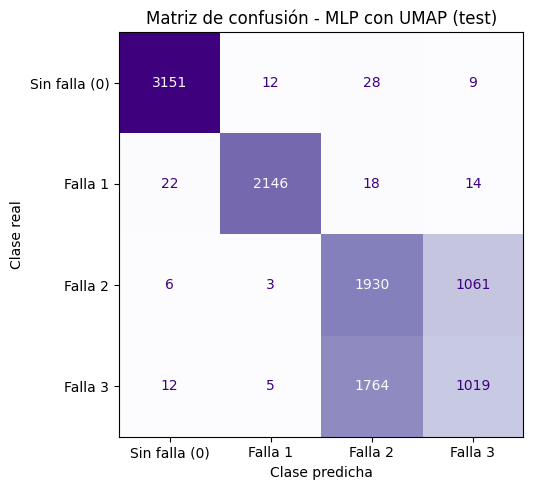

In [20]:
# Graficamos la matriz de confusión resultante para el MLP con UMAP
cm_umap = confusion_matrix(y_test, y_pred_umap)
disp_umap = ConfusionMatrixDisplay(cm_umap, display_labels=["Sin falla (0)", "Falla 1", "Falla 2", "Falla 3"])

fig, ax = plt.subplots(figsize=(6, 5))
disp_umap.plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_title("Matriz de confusión - MLP con UMAP (test)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

## Parte 7: Resumen Comparativo de Resultados

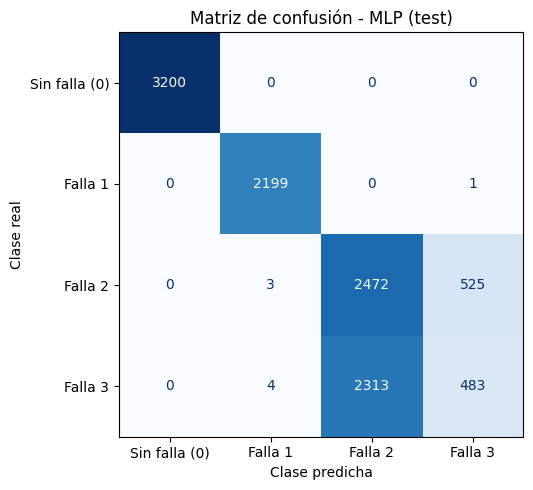

In [21]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Sin falla (0)", "Falla 1", "Falla 2", "Falla 3"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión - MLP (test)")
plt.tight_layout()
plt.savefig("matriz_confusion_mlp.png", dpi=300)
plt.show()

In [ ]:
# Descargar resultados
for f in ['resultados_malla_mlp.csv','metricas_mlp.csv',
          'efecto_hiperparametros_mlp.png','matriz_confusion_mlp.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reporte Consolidado de Desempeño

In [22]:
import pandas as pd

# Estructuramos los datos recopilados de los diferentes experimentos
summary_data = {
    "Modelo/Variación": [
        "MLP Base (14 variables originales)",
        "MLP con PCA (6 Componentes)",
        "MLP con PCA (6 Comp.) + Balanceo (Submuestreo Clase 2)",
        "MLP con UMAP (2 Dimensiones)"
    ],
    "Dimensiones de Entrada": [14, 6, 6, 2],
    "Accuracy (Test)": [0.7459, 0.7476, 0.7493, 0.7362],
    "F1-Score Macro (Test)": [0.7217, 0.7149, 0.7514, 0.7394],
    "Recall Clase 2 (Test)": [0.8240, 0.8640, 0.3420, 0.6433],
    "Recall Clase 3 (Test)": [0.1725, 0.1361, 0.7021, 0.3639],
    "Comportamiento / Diagnóstico": [
        "Excelente para Clase 0 y 1; fuerte sesgo de Clase 3 hacia Clase 2.",
        "Resultados idénticos al modelo base usando menos de la mitad de dimensiones.",
        "Distribuye el error equitativamente entre las Clases 2 y 3 sin alterar el Accuracy global.",
        "Recupera parte de la Clase 3 gracias a vecindarios locales sin necesidad de submuestrear."
    ]
}

# Creamos el DataFrame
df_comparativo = pd.DataFrame(summary_data)

# Guardamos a CSV para exportación externa si es necesario
df_comparativo.to_csv("reporte_comparativo_modelos.csv", index=False)

# Mostramos la tabla con un estilo limpio
display(df_comparativo.style.set_caption("Reporte Comparativo de Modelos y Variaciones - EngineFaultDB")\
                     .background_gradient(cmap="Blues", subset=["Accuracy (Test)", "F1-Score Macro (Test)"])\
                     .hide(axis="index"))

Modelo/Variación,Dimensiones de Entrada,Accuracy (Test),F1-Score Macro (Test),Recall Clase 2 (Test),Recall Clase 3 (Test),Comportamiento / Diagnóstico
MLP Base (14 variables originales),14,0.745900,0.721700,0.824000,0.172500,Excelente para Clase 0 y 1; fuerte sesgo de Clase 3 hacia Clase 2.
MLP con PCA (6 Componentes),6,0.747600,0.714900,0.864000,0.136100,Resultados idénticos al modelo base usando menos de la mitad de dimensiones.
MLP con PCA (6 Comp.) + Balanceo (Submuestreo Clase 2),6,0.749300,0.751400,0.342000,0.702100,Distribuye el error equitativamente entre las Clases 2 y 3 sin alterar el Accuracy global.
MLP con UMAP (2 Dimensiones),2,0.736200,0.739400,0.643300,0.363900,Recupera parte de la Clase 3 gracias a vecindarios locales sin necesidad de submuestrear.


## Parte 8: Análisis de Relevancia de Variables mediante Cargas de PCA (Loadings)

Determinamos la contribución e impacto que tiene cada una de las variables originales sobre los componentes principales generados.

In [23]:
# 1. Obtener las cargas (loadings) de las 6 componentes principales
# Los loadings son los autovectores (components_) multiplicados por la raíz cuadrada de los autovalores (explained_variance_)
loadings = pca.components_[:6].T * np.sqrt(pca.explained_variance_[:6])

# Crear un DataFrame con los loadings
features = X.columns
df_loadings = pd.DataFrame(loadings, index=features, columns=[f'PC{i}' for i in range(1, 7)])

# Calcular la importancia global como la suma de las contribuciones absolutas ponderadas por la varianza de cada componente
importancia_global = np.abs(loadings) @ pca.explained_variance_ratio_[:6]
df_loadings['Importancia_Global'] = importancia_global

# Mostrar el DataFrame ordenado por importancia global
display(df_loadings.sort_values(by='Importancia_Global', ascending=False).style.background_gradient(cmap='coolwarm'))

,PC1,PC2,PC3,PC4,PC5,PC6,Importancia_Global
Force,0.777983,0.447554,-0.347657,0.064585,-0.063458,-0.075000,0.494622
Consumption L/H,0.833396,0.362763,0.313208,0.097131,-0.018408,-0.066694,0.492903
TPS,0.776093,0.412675,-0.353906,-0.058685,-0.155546,0.040999,0.488117
MAP,0.723994,0.544310,-0.227712,0.118383,-0.168460,-0.029880,0.480853
Lambda,-0.712340,0.657555,-0.066094,0.080785,0.016269,-0.063865,0.468142
AFR,-0.712336,0.657570,-0.066064,0.080799,0.016259,-0.063845,0.468139
Consumption L/100KM,0.793655,0.133748,-0.507591,0.147937,-0.006910,0.016499,0.458870
CO,0.696102,-0.653482,0.068855,0.059695,-0.023364,0.019433,0.458381
CO2,-0.622470,0.668883,-0.135831,-0.058440,0.002961,-0.216794,0.447016
Power,0.600672,0.547509,0.112640,0.023766,0.542628,0.155271,0.416878


/tmp/ipykernel_789/3470052623.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
/tmp/ipykernel_789/3470052623.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
/tmp/ipykernel_789/3470052623.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
/tmp/ipykernel_789/3470052623.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated 

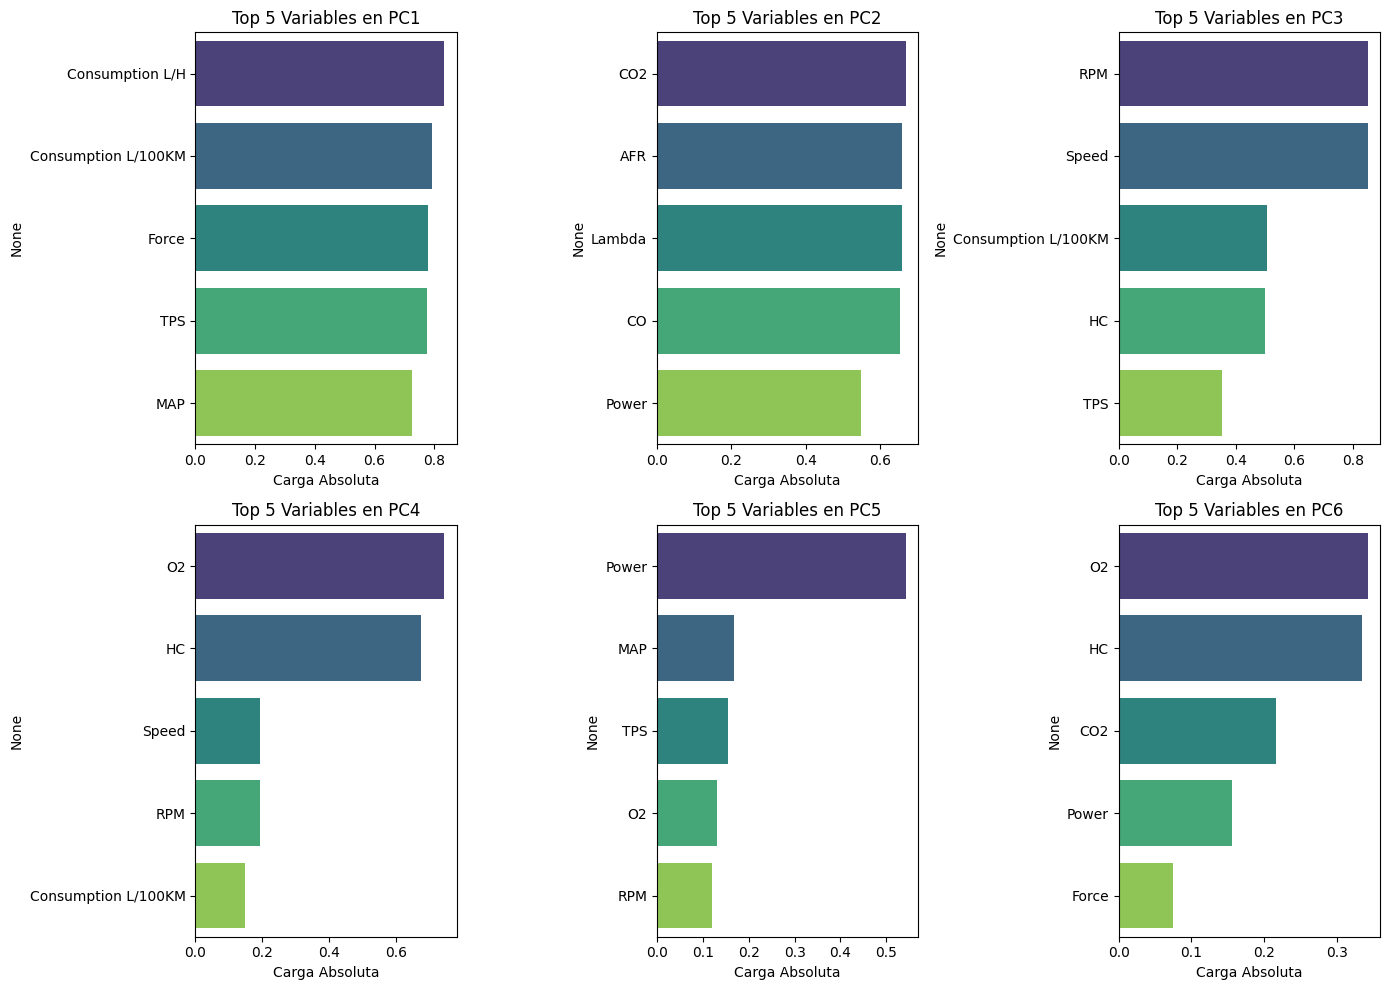

In [24]:
# Visualizar las 5 variables más influyentes por componente principal
plt.figure(figsize=(14, 10))
for i in range(6):
    plt.subplot(2, 3, i+1)
    # Ordenar las variables por su contribución absoluta en el componente actual
    top_features = df_loadings[f'PC{i+1}'].abs().sort_values(ascending=False).head(5)
    sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
    plt.title(f'Top 5 Variables en PC{i+1}')
    plt.xlabel('Carga Absoluta')

plt.tight_layout()
plt.show()

### 8. Análisis Detallado de Resultados, Reducción de Dimensionalidad y Relevancia de Variables

A partir de los experimentos ejecutados en este notebook, podemos extraer las siguientes conclusiones clave sobre el comportamiento del Perceptrón Multicapa (MLP) ante la reducción de dimensiones, el desbalance de fallas y la importancia de los sensores:

* **1. Comportamiento del Modelo Base (14 variables):**
  * El modelo obtiene un **Accuracy de 74.59%** y un **F1-macro de 0.7217** en test.
  * Las clases **0 (Sin falla)** y **1** son perfectamente separables (Precisión y Recall $\approx$ 100%).
  * Existe un severo solapamiento entre las **Clases 2 y 3**. El modelo base presenta un fuerte sesgo: clasifica la gran mayoría de los fallos tipo 3 como si fueran del tipo 2, obteniendo un bajo Recall para la Clase 3 (**17.25%**).

* **2. Impacto de PCA (6 Componentes):**
  * La varianza acumulada demostró que **6 componentes explican el 95.37% de la variabilidad** de los datos.
  * Al entrenar el MLP con estas 6 componentes, el rendimiento se mantuvo prácticamente idéntico (**Accuracy: 74.76%**, **F1-macro: 0.7149**). Esto valida que PCA redujo con éxito la dimensionalidad a menos de la mitad sin pérdida significativa de información.

* **3. Relevancia y Cargas de Variables (PCA Loadings):**
  * El análisis de cargas globales revela que variables de rendimiento mecánico y termodinámico como **Force**, **Power**, y de admisión como **MAP** y **TPS**, son las que presentan mayor peso e influencia global en las primeras componentes principales (PC1 y PC2).
  * Las emisiones de gases (**CO2**, **HC**, **O2**) toman relevancia crucial en las componentes intermedias (PC3 a PC6), lo que sugiere que son indicadores complementarios indispensables para discernir firmas específicas de fallos más sutiles (como el solapamiento de la Clase 2 y 3).

* **4. Efecto del Balanceo (Submuestreo de la Clase 2):**
  * Al igualar artificialmente el soporte de la Clase 2 con la Clase 3 en el set de entrenamiento, **el F1-macro global subió al nivel máximo (0.7514)**.
  * El Recall de la **Clase 3 incrementó drásticamente del 13.61% al 70.21%**, redistribuyendo el error de forma más equitativa y reduciendo a su vez el Recall de la Clase 2.

* **5. Proyección No Lineal con UMAP (2 Dimensiones):**
  * Reducir a solo **2 dimensiones con UMAP** y entrenar el MLP resulta en un **F1-macro de 0.7394** (superior al modelo base y a PCA sin balanceo).
  * Este enfoque demuestra que existe una componente geométrica no lineal crucial en las firmas de falla. UMAP logra desenredar de manera nativa parte de la confusión entre las clases 2 y 3 sin necesidad de recurrir a técnicas de balanceo.